# 2.4 Группировки, сводные таблицы, соединения — код страницы

Аналитика 101 · блок «Дата аналитика» · тема 02 «Pandas и подготовка данных» · страница 2.4.

В ноутбуке четыре блока раздела «Код»: когорты, сводная, соединение и `melt`. Они идут подряд и берут переменные друг у друга.

**Данные.** Три учебных файла должны лежать рядом с ноутбуком в папке `data`: `orders.csv` (32 заказа, 25 оплаченных), `countries.csv` и `managers.csv`. Их делает `data/gen.py` с зерном 186. Зерно подобрано перебором, условия отбора записаны в том же файле.

Вывод под ячейками получен на Python 3.13, pandas 3.0 и seaborn 0.13. Последняя ячейка рисует график и сохраняет его в `revenue_by_channel.png`.

In [1]:
import platform

import pandas as pd

print("Python", platform.python_version(), "| pandas", pd.__version__)

Python 3.13.18 | pandas 3.0.5


### Когорты через groupby: transform ставит когорту, agg сворачивает

In [2]:
import pandas as pd

orders = pd.read_csv("data/orders.csv", parse_dates=["date"])  # учебная выгрузка, 32 заказа
paid = orders[orders["status"] == "paid"].copy()                # 25 оплаченных
paid["month"] = paid["date"].dt.to_period("M")                  # 2026-01, 2026-02, 2026-03

# transform: месяц первой оплаты клиента — в каждую строку этого клиента
paid["cohort"] = paid.groupby("customer_id")["month"].transform("min")

# agg с именованными агрегатами: одна строка на когорту
cohorts = paid.groupby("cohort").agg(
    customers=("customer_id", "nunique"),   # уникальные клиенты
    orders=("order_id", "size"),            # число заказов
    revenue=("amount", "sum"),              # выручка, ₽
)
cohorts["per_customer"] = (cohorts["revenue"] / cohorts["customers"]).round()
print(cohorts)
print()

# сколько клиентов каждой когорты платили в каждом месяце
active = paid.groupby(["cohort", "month"])["customer_id"].nunique().unstack()
print(active)

         customers  orders  revenue  per_customer
cohort                                           
2026-01          6      12    38370        6395.0
2026-02          5       7    24680        4936.0
2026-03          4       6    16380        4095.0

month    2026-01  2026-02  2026-03
cohort                            
2026-01      6.0      3.0      3.0
2026-02      NaN      5.0      1.0
2026-03      NaN      NaN      4.0


Январская когорта — 6 клиентов и почти половина выручки. В нижней таблице NaN под диагональю: клиент не может платить раньше месяца своей первой оплаты.

### pivot_table месяц × канал с итогами, а pivot падает на повторах

In [3]:
by_month = paid.pivot_table(
    index="month", columns="channel", values="amount",
    aggfunc="sum",          # по умолчанию было бы среднее
    fill_value=0,           # пустую ячейку — нулём, а не NaN
    margins=True, margins_name="Итого",
)
print(by_month)
print()

try:
    paid.pivot(index="month", columns="channel", values="amount")
except ValueError as e:
    print("pivot:", e)

channel  органика  рассылка  реклама  Итого
month                                      
2026-01      6600         0    11090  17690
2026-02     10890      5570    13280  29740
2026-03     16910      6400     8690  32000
Итого       34400     11970    33060  79430

pivot: Index contains duplicate entries, cannot reshape


Правый нижний угол — 79 430 ₽, как в сцене. Без fill_value ячейка «январь × рассылка» была бы NaN, а столбец рассылки — float.

### merge с индикатором и validate ловит дубль, который принёс concat

In [4]:
countries = pd.read_csv("data/countries.csv")   # справочник: country, name, currency

full = paid.merge(countries, on="country", how="left",
                  indicator=True, validate="many_to_one")
print(len(paid), "->", len(full))
print(full["_merge"].value_counts())
lost = full[full["_merge"] == "left_only"]
print("без пары:", lost["order_id"].tolist(), "страна:", lost["country"].unique().tolist())
print()

# справочник дополнили новой выгрузкой, и Россия попала в него дважды
extra = pd.DataFrame({"country": ["UZ", "RU"], "name": ["Узбекистан", "Россия"],
                      "currency": ["UZS", "RUB"]})
countries2 = pd.concat([countries, extra], ignore_index=True)
print("строк без проверки:", len(paid.merge(countries2, on="country", how="left")))
try:
    paid.merge(countries2, on="country", how="left", validate="many_to_one")
except pd.errors.MergeError as e:
    print("MergeError:", e)

countries2 = countries2.drop_duplicates("country", keep="last")
fixed = paid.merge(countries2, on="country", how="left", validate="many_to_one")
print("после дедупликации:", len(fixed), "строк, NaN в name:", fixed["name"].isna().sum())

25 -> 25
_merge
both          20
left_only      5
right_only     0
Name: count, dtype: int64
без пары: [1002, 1014, 1015, 1018, 1024] страна: ['UZ']

строк без проверки: 33
MergeError: Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
 country
     RU ...
после дедупликации: 25 строк, NaN в name: 0


Пять заказов из Узбекистана получили NaN: его нет в справочнике. MergeError печатает и сами дубли — здесь RU.

### melt: из широкой сводной — длинная таблица для графика

(3, 3) -> (9, 3)
     month   channel  revenue
0  2026-01  органика     6600
1  2026-02  органика    10890
2  2026-03  органика    16910
3  2026-01  рассылка        0
4  2026-02  рассылка     5570
5  2026-03  рассылка     6400
6  2026-01   реклама    11090
7  2026-02   реклама    13280
8  2026-03   реклама     8690


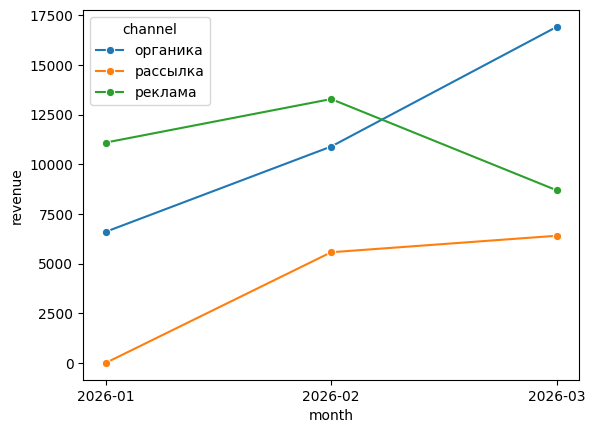

In [5]:
wide = paid.pivot_table(index="month", columns="channel",
                        values="amount", aggfunc="sum", fill_value=0)
long = wide.reset_index().melt(id_vars="month", var_name="channel",
                               value_name="revenue")
print(wide.shape, "->", long.shape)
print(long)

import seaborn as sns                      # seaborn ждёт длинный формат
long["month"] = long["month"].astype(str)
ax = sns.lineplot(data=long, x="month", y="revenue", hue="channel", marker="o")
ax.figure.savefig("revenue_by_channel.png", dpi=120)

В марте органика обогнала рекламу06 00012 00018 0002026-012026-022026-03органикарассылкарекламаТа же картинка, что строит seaborn: по линии на канал, ось Y — revenue, ₽. Перерисовано по выводу melt.